<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200"/>
</p></center>

<center><font size=10>Advanced Agentic AI for Business Applications</center></font>
<center><font size=10>Transformers and Attention Mechanisms</center></font>

<center><p float="center">
  <img src="https://images.pexels.com/photos/6411/smartphone-girl-typing-phone.jpg" width="640"/>
</p></center>

<center><font size=6>Multilingual Customer Support Triage Pipeline
</center></font>




## **Problem Statement**

### Business Context

**MeshLink Technologies**, an Austin-based consumer electronics and SaaS company, sells Wi-Fi routers, smart home devices, and a companion mobile and desktop application. The company operates a centralized English-speaking customer support organization, but its customers are spread across dozens of countries and submit support tickets in many languages, including Hindi, Spanish, French, German, Portuguese, and others.

The support organization is facing four major operational challenges.

- **First, language fragmentation.** A significant share of incoming tickets arrives in languages that the company's support systems and agents cannot efficiently process. These tickets either wait for a limited number of bilingual agents or go through inconsistent manual translation, increasing overall query resolution time and potentially degrading response quality.

- **Second, a high volume of repetitive low-complexity tickets.** Approximately 40 to 60 percent of consumer technology support tickets consist of generic, self-contained technical questions that require no customer account information, billing data, or policy interpretation. Examples include:
  - How to connect a router?
  - Why a device will not join Wi-Fi
  - What file formats the app supports.
  
  These questions can be answered from the company's own product and troubleshooting documentation.

- **Third, the lack of an automated first-stage filter.** Every ticket, whether simple or complex, follows the same downstream support workflow. As a result, repetitive technical questions consume the same expensive support resources as complex requests such as refunds, warranty claims, account management, and escalated complaints. This increases cost per ticket, lengthens queues, and reduces the availability of downstream systems for cases that genuinely require them.

- **Fourth, inconsistent triage.** Every incoming ticket must be read, understood, and categorized before it can be processed. Manual triage is slow, subjective, and difficult to scale during product launches, service outages, or seasonal spikes in ticket volume.

The result is slower first response times, higher operating costs, inconsistent service quality across languages, and inefficient use of downstream support resources.

The VP of Customer Operations wants an automated first-stage triage pipeline that translates every ticket into English, classifies its intent, automatically resolves technical questions using answers grounded in the company's product documentation, and routes everything else, together with the canonical English version and predicted category, to a human agent.

### MeshLink Product Catalog

To keep the case study concrete, the pipeline is built against the following MeshLink product line. These names are used consistently throughout the notebook and in the knowledge base.

| Product | Type | Description |
|---------|------|-------------|
| **MeshLink Nova R7** | Wi-Fi router | Flagship tri-band mesh router |
| **MeshLink Mini M3** | Wi-Fi router | Compact single-unit router for small homes |
| **MeshLink SmartPlug S1** | Smart home device | Wi-Fi controllable power plug |
| **MeshLink Cam C2** | Smart home device | Indoor security camera |
| **MeshLink Home** | Mobile and desktop app | Companion app to set up and control all devices |

### Scope: First-Response System Only

This pipeline is strictly limited to the customer's initial support ticket.

* If a ticket is a technical question and a confident answer is found in the MeshLink knowledge base, the system generates and sends a single grounded response in the customer's original language.
* If the ticket is about billing or account matters, or if no confident answer is found in the knowledge base, it is routed immediately to a human agent.
* If the customer replies to an automated response for any reason, the system stops all automation. The complete conversation is translated into canonical English and routed directly to a human agent. No second automated response is generated.

The pipeline never supports multi-turn conversations. It either sends one grounded first response or routes the ticket once. Every follow-up becomes the responsibility of a human agent.

This boundary keeps the automation limited to high-confidence, single-response scenarios and prevents the model from handling account-specific, policy-sensitive, or escalating conversations.

### Objective

Build a POC for an automated first-response triage pipeline that intercepts every incoming support ticket, automatically resolves technical questions with a single documentation-grounded response, and routes everything else to a human agent.

Specifically, the system must:

**Normalize language**
* Translate every incoming ticket into a single canonical language, English.
* Produce one authoritative English version that is reused by the classifier, the retriever, the answer generator, and the human agent.

**Understand and categorize**
* Classify each ticket into one of two intent categories: Product and Technical Support, or Billing and Account.
* Billing and Account tickets are always routed to a human.

**Automatically resolve technical questions with retrieval (RAG)**
* For Product and Technical Support tickets, embed the question and retrieve the most relevant entries from the MeshLink knowledge base.
* Generate one answer that is grounded strictly in the retrieved documentation, then translate it back into the customer's original language and send it as the first response.

**Escalate when the answer is not found**
* If retrieval does not return a sufficiently similar knowledge base entry, or if the generation model reports that the answer is not contained in the retrieved documentation, route the ticket to a human agent instead of guessing.

**Hand all follow-up conversations to humans**
* If the customer responds after receiving the automated first response, translate the new message and conversation history into English and route everything directly to a human agent.
* No additional automated responses are generated.

### Scope Boundary

* The first-response stage answers technical questions only from the curated MeshLink knowledge base, not from customer account data and not from the model's open-ended memory.
* The system does not perform customer account lookup, policy interpretation, or multi-turn conversations.
* Any ticket about billing or accounts, any question not covered by the knowledge base, and any follow-up customer response is routed to a human agent.

This strict boundary makes the solution safe, predictable, and operationally defensible.

## **Pipeline Architecture**

This case study is built around the three families of transformer models introduced this week. Each stage uses the family whose architecture is genuinely suited to that stage's job. In this version the encoder-only family is used for two different jobs: classifying the ticket, and producing the embeddings that power retrieval.

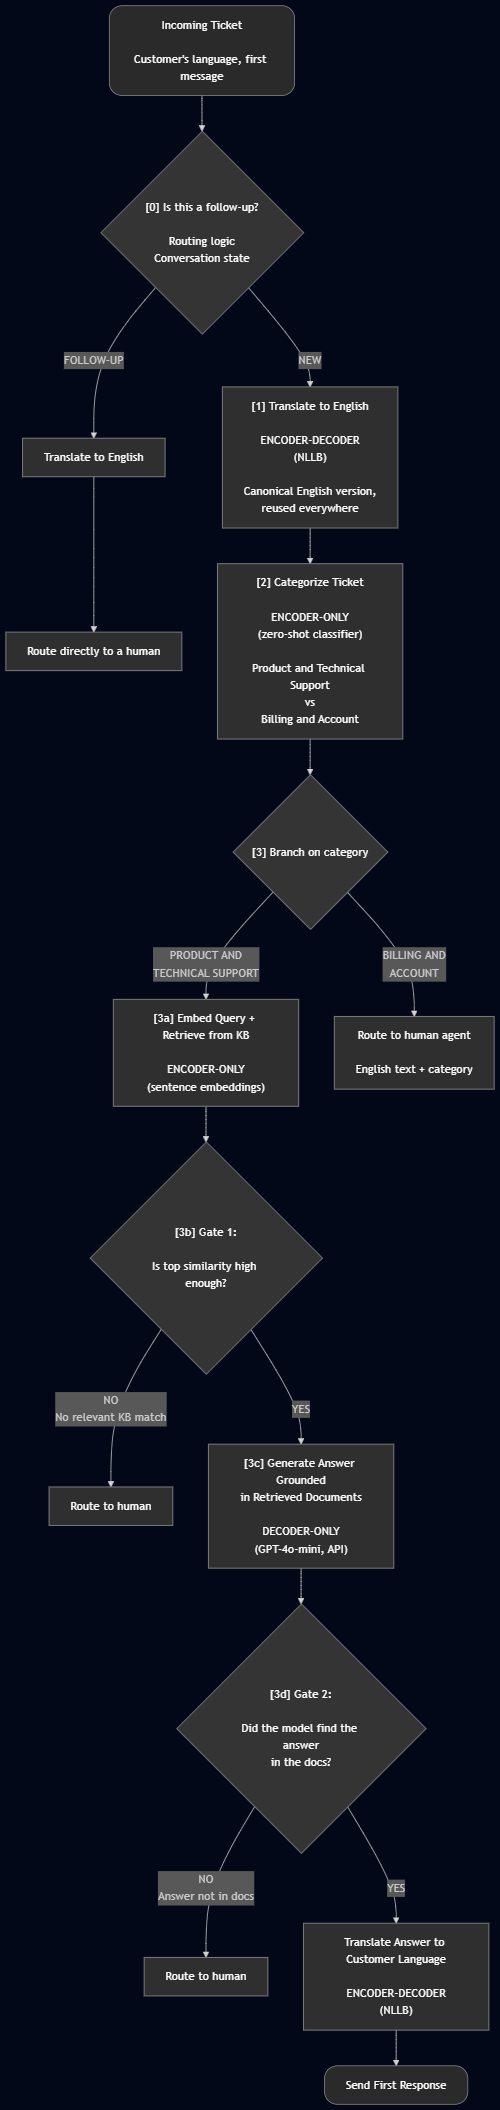


| Stage | Job | Transformer family | Model / component |
|-------|-----|--------------------|-------------------|
| 0 | Follow-up detection | Routing logic | Conversation state flag |
| 1 | Translate ticket to English | **Encoder-decoder** | `facebook/nllb-200-distilled-600M` |
| 2 | Categorize ticket | **Encoder-only** | `facebook/bart-large-mnli` (zero-shot) |
| 3a | Embed query and retrieve | **Encoder-only** | `sentence-transformers/all-MiniLM-L6-v2` |
| 3b | Similarity gate | Routing logic | Cosine similarity threshold |
| 3c | Generate grounded answer | **Decoder-only (API)** | OpenAI `gpt-4o-mini` |
| 3d | Answer-not-found gate | Routing logic | Model signals coverage |
| 4 | Translate answer to customer language | **Encoder-decoder** | `facebook/nllb-200-distilled-600M` |

### Why each transformer family fits its stage

**Encoder-decoder for translation.** Translation maps one full sequence to a different full sequence. The encoder reads the entire source sentence bidirectionally to build meaning, and the decoder generates the target sentence one token at a time. This sequence-to-sequence shape is exactly what encoder-decoder models were designed for.

**Encoder-only for understanding and for embeddings.** Both classification and retrieval are understanding tasks. For classification, the model reads the whole ticket and produces a label. For retrieval, the model turns text into a dense vector so that similar meanings sit close together, which is what makes semantic search possible. Neither task generates text, so an encoder is the efficient and accurate choice for both.

**Decoder-only for grounded answer generation.** Writing the support reply is open-ended, left-to-right text generation. Here the decoder is additionally constrained to use only the retrieved documentation, which keeps the answer accurate and lets it declare when the documentation does not contain the answer.

## **Design Question: Could One Decoder-Only Model Do Everything?**

A natural objection is that GPT-4o-mini is a powerful decoder-only model that could translate, classify, embed, and answer on its own, so why introduce separate translation, classification, and embedding models at all.

A single decoder-only model **could** technically do most of these jobs, and it could answer from its own memory without retrieval. The question is not whether it *can*, but whether it *should* at production scale. The design comes down to four practical factors: **cost, latency, control, and reliability.**

### 1. Cost

A large general-purpose model is billed per token and is the most expensive component per call. The mechanical stages of this pipeline do not need that horsepower.

* **Classification** is the clearest example. Sending every ticket to a paid large model just to receive a one-word category label is wasteful. A small encoder produces the same label for a tiny fraction of the cost.
* **Embeddings** for retrieval are cheap and fast on a small local sentence-embedding model, and can be precomputed once for the knowledge base.
* **Translation** with a dedicated model is cheaper and more predictable than paying a large general model to translate.

The principle: pay large-model prices only for the one job that needs a large model, which is grounded answer generation. The cell below makes this concrete with editable numbers.

In [1]:
# Illustrative cost comparison (sourced numbers, edit freely).
# The reasoning is the lesson; figures are grounded but approximate.

tickets_per_day  = 10000     # daily ticket volume
tech_share       = 0.50      # fraction classified as technical (RAG path)
answerable_share = 0.70      # of those, fraction the KB can actually answer

# =============================================================
# TOKEN ASSUMPTIONS for the decoder model (gpt-4o-mini)
# Prompt is SMALL (short support ticket + brief instruction), so:
#   ~250 input tokens  (system + short ticket/query + a little context)
#   ~150 output tokens (concise answer)
# gpt-4o-mini list price: $0.15 / 1M input, $0.60 / 1M output (OpenAI, 2026)
# =============================================================
IN_TOKENS  = 250
OUT_TOKENS = 150
LLM_CALL_COST = (IN_TOKENS/1e6)*0.15 + (OUT_TOKENS/1e6)*0.60   # = $0.0001275/call

# --- Self-hosted per-call costs: GPU_hr / (3600 / latency_sec) ---
# NVIDIA L4 @ ~$0.60/GPU-hr on-demand. Latencies are typical batch=1 estimates
# for these model sizes — BENCHMARK YOURS, this is the main cost driver.
GPU_HR = 0.60
NLLB_CALL_COST    = GPU_HR / (3600 / 0.200)   # nllb-600M,  ~200ms -> $0.0000333
ENCODER_CALL_COST = GPU_HR / (3600 / 0.120)   # bart-mnli,  ~120ms -> $0.0000200
EMBED_CALL_COST   = GPU_HR / (3600 / 0.020)   # MiniLM-22M,  ~20ms -> $0.0000033

tech     = int(tickets_per_day * tech_share)
answered = int(tech * answerable_share)

# Approach A: large decoder-only model for translate + classify + answer + translate-back
approach_a = (
    tickets_per_day * LLM_CALL_COST     # translate inbound
    + tickets_per_day * LLM_CALL_COST   # classify
    + tech * EMBED_CALL_COST
    + answered * LLM_CALL_COST          # generate answer
    + answered * LLM_CALL_COST          # translate answer back
)

# Approach B: specialized models for translate + classify + embed, LLM only for grounded generation
approach_b = (
    tickets_per_day * NLLB_CALL_COST        # translate inbound (NLLB)
    + tickets_per_day * ENCODER_CALL_COST   # classify (encoder)
    + tech * EMBED_CALL_COST                # embed query for retrieval
    + answered * LLM_CALL_COST              # grounded generation (LLM - its only job)
    + answered * NLLB_CALL_COST             # translate answer back (NLLB)
)

print(f"Assumed decoder tokens: {IN_TOKENS} in / {OUT_TOKENS} out  ->  ${LLM_CALL_COST:.6f}/LLM call\n")
print(f"Tickets/day: {tickets_per_day:,} | technical: {tech:,} | KB-answered: {answered:,}\n")
print(f"Approach A  (LLM for everything)          : ${approach_a:,.2f}/day  ->  ${approach_a*30:,.2f}/month")
print(f"Approach B  (specialized + LLM-generation): ${approach_b:,.2f}/day  ->  ${approach_b*30:,.2f}/month")
print(f"\nApproach B is ~{approach_a/approach_b:,.1f}x cheaper per day with these numbers.")

Assumed decoder tokens: 250 in / 150 out  ->  $0.000127/LLM call

Tickets/day: 10,000 | technical: 5,000 | KB-answered: 3,500

Approach A  (LLM for everything)          : $3.46/day  ->  $103.77/month
Approach B  (specialized + LLM-generation): $1.11/day  ->  $33.39/month

Approach B is ~3.1x cheaper per day with these numbers.


### 2. Latency, Control, and Reliability

**Latency.** Small translation, classification, and embedding models return in milliseconds on local hardware. Routing every stage through an external API adds network round-trips and rate-limit exposure, and several sequential API calls compound that delay for every ticket.

**Control and determinism.** A dedicated classifier gives a fixed set of categories and a confidence score the team owns and can tune. Retrieval with a similarity threshold gives a deterministic, inspectable gate. Because our routing must be conservative and predictable, this control is a safety feature, not a limitation.

**Reliability and grounding.** Retrieval keeps answers tied to approved documentation instead of the model's open memory, which prevents confident but wrong answers about specific products. If the external API is unavailable, the local stack can still translate, classify, and retrieve, so the system degrades gracefully.

### When Using One Model For Everything Is Actually Reasonable

To stay intellectually honest, the single-model approach genuinely wins in some situations:

* **Low volume.** If the system handles only a few hundred tickets a day, the cost gap is negligible and the overhead of hosting separate models is not worth it.
* **Rapid prototyping.** A single model call is the fastest way to validate the idea before investing in a specialized stack.
* **No labeled data or no knowledge base.** If there is nothing to fine-tune on or retrieve from, a capable general model is a reasonable starting point.

The decision depends on **volume, cost per call, how much control the routing needs, and whether answers must be grounded in approved documentation.** This is why all three transformer families continue to coexist in industry: each sits at a different point on the capability-versus-cost curve.

## **Installing and Importing Necessary Libraries and Dependencies**

In [4]:
!pip install -q transformers \
                torch \
                sentencepiece \
                sacremoses \
                sentence-transformers \
                openai

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This message can be ignored, as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [3]:
import os
import json
import warnings

import numpy as np
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,   # encoder-decoder family (translation)
    pipeline,                # encoder-only zero-shot classifier
)
from sentence_transformers import SentenceTransformer  # encoder-only embeddings for retrieval
from openai import OpenAI    # decoder-only family, accessed via API

warnings.filterwarnings("ignore")

DEVICE = 0 if torch.cuda.is_available() else -1
print("Torch:", torch.__version__, "| GPU available:", torch.cuda.is_available())

Torch: 2.14.1+cpu | GPU available: False


## **Model Initialization**

### OpenAI API Calling

The decoder-only stage uses the OpenAI API. Credentials are read from a `config.json` file placed next to the notebook, rather than being hardcoded.

```
{
  "OPENAI_API_KEY": "your-openai-key",
  "OPENAI_BASE_URL": "your-openai-base"
}
```

In [12]:
# Load credentials from the configuration file and set them as environment variables.
file_name = "config.json"                                  # Name of the configuration file
with open(file_name, "r") as file:                         # Open the config file in read mode
    config = json.load(file)                               # Load the JSON content as a dictionary
    OPENAI_API_KEY = config.get("OPENAI_API_KEY")          # Extract the API key
    OPENAI_BASE_URL = config.get("OPENAI_BASE_URL")        # Extract the API base URL

os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY              # Set the API key as an environment variable
os.environ["OPENAI_BASE_URL"] = OPENAI_BASE_URL            # Set the API base URL as an environment variable

client = OpenAI()                                          # Decoder-only model is called through this client
GEN_MODEL = "gpt-4o-mini"                                  # The decoder-only generation model
print("OpenAI client ready. Generation model:", GEN_MODEL)

OpenAI client ready. Generation model: gpt-4o-mini


### Supported Languages

NLLB identifies languages using FLORES-200 codes. We define a small map for the languages named in the business problem. Extending the pipeline to more languages is simply a matter of adding entries here.

In [13]:
# Map from a friendly language name to its FLORES-200 code used by NLLB.
LANG_CODES = {
    "English":    "eng_Latn",
    "Hindi":      "hin_Deva",
    "Spanish":    "spa_Latn",
    "French":     "fra_Latn",
    "German":     "deu_Latn",
    "Portuguese": "por_Latn",
}
for name, code_ in LANG_CODES.items():
    print(f"{name:12s} -> {code_}")

English      -> eng_Latn
Hindi        -> hin_Deva
Spanish      -> spa_Latn
French       -> fra_Latn
German       -> deu_Latn
Portuguese   -> por_Latn


## **MeshLink Knowledge Base (Troubleshooting Documentation)**

This is a basic troubleshooting and debugging document set for the MeshLink product line. In production this would be a much larger, continuously updated knowledge base, possibly stored in a dedicated vector database. For this case study a small in-memory list is enough to demonstrate retrieval and the answer-not-found gate.

In [14]:
# Each KB entry has an id, a short title, and the body text used for answering.
# Only these documents may be used to answer technical questions.
KNOWLEDGE_BASE = [
    {
        "id": "KB-01",
        "title": "Reset the MeshLink Nova R7 router to factory settings",
        "text": (
            "To factory reset the MeshLink Nova R7, make sure it is powered on. "
            "Locate the small recessed Reset button on the back of the unit. "
            "Using a paperclip, press and hold the Reset button for 10 seconds until "
            "the front LED turns red and then starts blinking white. Release the button "
            "and wait about two minutes for the router to reboot. The router is now reset "
            "to factory defaults and can be set up again from the MeshLink Home app."
        ),
    },
    {
        "id": "KB-02",
        "title": "MeshLink Nova R7 will not power on",
        "text": (
            "If the MeshLink Nova R7 shows no LED at all, first confirm the power adapter "
            "is the original MeshLink adapter and is firmly connected at both the wall outlet "
            "and the router. Try a different known-working wall outlet. If the LED still does "
            "not light up after connecting to a working outlet, the power adapter may be faulty "
            "and should be replaced with an official MeshLink adapter."
        ),
    },
    {
        "id": "KB-03",
        "title": "A device will not connect to MeshLink Wi-Fi",
        "text": (
            "If a phone or laptop cannot join the MeshLink Wi-Fi network, first move the device "
            "closer to the router to rule out range issues. Confirm you are selecting the correct "
            "network name and entering the current Wi-Fi password exactly, including capitalization. "
            "Toggle the device Wi-Fi off and on, then forget the network and rejoin it. If other "
            "devices connect but one does not, restart that single device before trying again."
        ),
    },
    {
        "id": "KB-04",
        "title": "Set up a new MeshLink Mini M3 for the first time",
        "text": (
            "To set up the MeshLink Mini M3, plug it into a power outlet and wait for the LED to "
            "blink white, which means it is ready for setup. Open the MeshLink Home app, sign in, "
            "and tap Add Device. Choose MeshLink Mini M3 from the list and follow the on-screen steps. "
            "The app will connect to the Mini M3, ask you to name your network, and set a Wi-Fi password. "
            "Setup is complete when the LED turns solid white."
        ),
    },
    {
        "id": "KB-05",
        "title": "Pair the MeshLink SmartPlug S1 with the app",
        "text": (
            "To pair the MeshLink SmartPlug S1, plug it into an outlet and wait for its LED to blink. "
            "In the MeshLink Home app, tap Add Device and select MeshLink SmartPlug S1. Keep your phone "
            "near the plug during pairing. Once pairing succeeds, the LED turns solid and the plug appears "
            "in your device list, where you can turn it on or off and set schedules."
        ),
    },
    {
        "id": "KB-06",
        "title": "MeshLink Cam C2 shows a black or frozen video feed",
        "text": (
            "If the MeshLink Cam C2 live feed is black or frozen, first check that the camera LED is on. "
            "In the MeshLink Home app, close and reopen the camera view. If the feed does not recover, "
            "power cycle the camera by unplugging it for ten seconds and plugging it back in. A weak "
            "Wi-Fi signal at the camera location can also cause a frozen feed, so consider moving the "
            "camera closer to the router."
        ),
    },
    {
        "id": "KB-07",
        "title": "Update firmware on MeshLink devices",
        "text": (
            "MeshLink devices update firmware through the MeshLink Home app. Open the app, go to the "
            "device, and open its Settings. If an update is available you will see an Update Firmware "
            "option. Keep the device powered on and do not close the app during the update. The device "
            "may restart once when the update finishes."
        ),
    },
    {
        "id": "KB-08",
        "title": "Change the display language in the MeshLink Home app",
        "text": (
            "To change the display language in the MeshLink Home app, open the app and go to the Profile "
            "tab. Tap Settings, then tap Language. Choose your preferred language from the list. The app "
            "updates immediately and does not require a restart."
        ),
    },
    {
        "id": "KB-09",
        "title": "Supported video formats for MeshLink Cam C2 clip export",
        "text": (
            "Clips recorded by the MeshLink Cam C2 can be exported from the MeshLink Home app in MP4 format. "
            "Exported MP4 files can be saved to your phone or shared. The app does not export in other video "
            "formats."
        ),
    },
    {
        "id": "KB-10",
        "title": "MeshLink Nova R7 frequent Wi-Fi drops",
        "text": (
            "If the MeshLink Nova R7 network drops frequently, place the router in an open, elevated location "
            "away from thick walls, large metal objects, and microwaves. Make sure the firmware is up to date "
            "using the MeshLink Home app. If only one room has drops, a mesh extender may be needed to cover "
            "that area."
        ),
    },
    {
        "id": "KB-11",
        "title": "Connect the MeshLink Nova R7 to a new Wi-Fi network",
        "text": (
            "To point the MeshLink Nova R7 at a new Wi-Fi network or change its network name, "
            "open the MeshLink Home app and sign in. Go to the Nova R7 device, open its Settings, "
            "and select Wi-Fi Settings. Tap Edit Network, then enter the new network name (SSID) "
            "and Wi-Fi password you want the router to broadcast. Save the changes. The router will "
            "apply the new settings and restart once, which takes about two minutes, after which "
            "your devices can join using the new network name and password."
        ),
    },
    {
        "id": "KB-12",
        "title": "Change the Wi-Fi password on the MeshLink Nova R7",
        "text": (
            "To change the Wi-Fi password on the MeshLink Nova R7, open the MeshLink Home app and go "
            "to the Nova R7 device. Open Settings, then Wi-Fi Settings, then tap Change Password. "
            "Enter the new password and save. The router restarts briefly to apply the change. All "
            "previously connected devices must reconnect using the new password."
        ),
    },
]

print(f"Knowledge base loaded with {len(KNOWLEDGE_BASE)} entries.")

Knowledge base loaded with 12 entries.


## **Translate to English (Encoder-Decoder)**

***Prompt***:

<font size=3 color="#4682B4"><b> Build a translation function using the NLLB encoder-decoder model. Accept text, a source language code, and a target language code. The encoder reads the full source sentence and the decoder generates the translation. This same function is reused later to translate the generated answer back into the customer's language.
</font>

We load Meta's **NLLB** (No Language Left Behind), a sequence-to-sequence encoder-decoder model. It translates between many languages in both directions, so one model serves both the inbound translation (customer language to English) and the outbound translation (English answer back to the customer language).

In [15]:
# Encoder-decoder model for translation.
MODEL_TRANS = "facebook/nllb-200-distilled-600M"
trans_tokenizer = AutoTokenizer.from_pretrained(MODEL_TRANS)
trans_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_TRANS)
if DEVICE == 0:
    trans_model = trans_model.to("cuda")

def translate(text, src_code, tgt_code):
    """
    Translate text from src_code to tgt_code using the NLLB encoder-decoder model.

    Args:
        text:     The text to translate.
        src_code: FLORES-200 code of the source language (e.g. "spa_Latn").
        tgt_code: FLORES-200 code of the target language (e.g. "eng_Latn").

    Returns:
        The translated text as a string.
    """
    trans_tokenizer.src_lang = src_code
    encoded = trans_tokenizer(text, return_tensors="pt")
    if DEVICE == 0:
        encoded = {k: v.to("cuda") for k, v in encoded.items()}
    forced_bos = trans_tokenizer.convert_tokens_to_ids(tgt_code)
    generated = trans_model.generate(**encoded, forced_bos_token_id=forced_bos, max_length=256)
    return trans_tokenizer.batch_decode(generated, skip_special_tokens=True)[0]

# Quick check: Spanish to English
print(translate("Como conecto mi router a una nueva red Wi-Fi?", "spa_Latn", "eng_Latn"))

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (4 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

How do I connect my router to a new Wi-Fi network?


## **Categorize the Ticket (Encoder-Only)**

***Prompt***:

<font size=3 color="#4682B4"><b> Build a classification function using an encoder-only model. Read the canonical English ticket and assign it to one of two categories: Product and Technical Support, or Billing and Account. Billing and Account tickets are always routed to a human. Product and Technical Support tickets continue to the retrieval stage.
</font>

Ticket categorization is a text understanding task, making **encoder models** well suited due to their low latency and high throughput.

In this notebook, we use **zero-shot classification**.

> **Zero-shot classification** enables a pre-trained model to classify text into user-defined labels without requiring task-specific training. The model predicts the label that best matches the input based on its existing language understanding.

In [16]:
# Encoder-only model used here in a zero-shot classification setup.
zero_shot = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=DEVICE,
)

# Two intent categories.
CATEGORY_TECH = "Product and Technical Support"
CATEGORY_BILLING = "Billing and Account"
CANDIDATE_LABELS = [CATEGORY_TECH, CATEGORY_BILLING]

def categorize(english_text):
    """
    Classify an English ticket into one of the two categories.

    Returns a dict with:
        category   : best-matching category
        confidence : model confidence for that category (0-1)
    """
    result = zero_shot(english_text, CANDIDATE_LABELS, multi_label=False)
    return {
        "category": result["labels"][0],
        "confidence": round(float(result["scores"][0]), 3),
    }

# Quick check on two contrasting tickets
print(categorize("How do I connect my MeshLink Nova R7 to a new Wi-Fi network?"))
print(categorize("I was charged twice for my subscription and want a refund."))

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'category': 'Product and Technical Support', 'confidence': 0.784}
{'category': 'Billing and Account', 'confidence': 0.896}


The classifier correctly categorizes both example tickets and returns a confidence score indicating how strongly the predicted category matches the input.

- **"How do I connect my MeshLink Nova R7 to a new Wi-Fi network?"** -> **Product and Technical Support** (Confidence: **0.784**)
- **"I was charged twice for my subscription and want a refund."** -> **Billing and Account** (Confidence: **0.896**)

The confidence score ranges from **0 to 1**, where higher values indicate greater confidence in the predicted category.


## **Embed and Retrieve from the Knowledge Base (Encoder-Only)**

***Prompt***:

<font size=3 color="#4682B4"><b> Build a retriever using a sentence-embedding encoder model. Embed every knowledge base entry once, embed the incoming question, and return the most similar entries by cosine similarity together with the top similarity score. The top score is used as the first safety gate: if it is too low, no relevant answer exists and the ticket is routed to a human.
</font>

Retrieval uses an encoder-only sentence-embedding model (`all-MiniLM-L6-v2`). Each knowledge base entry is embedded once, up front. At query time we embed the question and compare it to every entry using cosine similarity. The most similar entries become the context for the answer generator, and the highest similarity score becomes our first gate.

In [17]:
# Encoder-only embedding model for semantic retrieval.
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# Precompute embeddings for every knowledge base entry (title + text).
KB_TEXTS = [f"{d['title']}. {d['text']}" for d in KNOWLEDGE_BASE]
KB_EMBEDDINGS = embedder.encode(KB_TEXTS, normalize_embeddings=True)

# First safety gate: minimum cosine similarity for the top result to count as a match.
SIMILARITY_THRESHOLD = 0.35

def retrieve(english_query, top_k=3):
    """
    Embed the query and return the top_k most similar KB entries.

    Returns a dict with:
        hits     : list of {id, title, text, score} sorted by similarity (highest first)
        top_score: the highest cosine similarity (used for the similarity gate)
    """
    q_emb = embedder.encode([english_query], normalize_embeddings=True)[0]
    sims = KB_EMBEDDINGS @ q_emb                      # cosine similarity (vectors are normalized)
    order = np.argsort(-sims)[:top_k]
    hits = [{
        "id": KNOWLEDGE_BASE[i]["id"],
        "title": KNOWLEDGE_BASE[i]["title"],
        "text": KNOWLEDGE_BASE[i]["text"],
        "score": round(float(sims[i]), 3),
    } for i in order]
    return {"hits": hits, "top_score": hits[0]["score"] if hits else 0.0}

# Quick check
r = retrieve("How do I factory reset my Nova R7 router?")
print("top_score:", r["top_score"])
for h in r["hits"]:
    print(f"  {h['id']} ({h['score']}) {h['title']}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

top_score: 0.739
  KB-01 (0.739) Reset the MeshLink Nova R7 router to factory settings
  KB-12 (0.625) Change the Wi-Fi password on the MeshLink Nova R7
  KB-11 (0.57) Connect the MeshLink Nova R7 to a new Wi-Fi network


## **Generate a Grounded Answer (Decoder-Only, API)**

***Prompt***:

<font size=3 color="#4682B4"><b> Build an answer-generation function that calls the decoder-only model through the OpenAI API. Provide the retrieved knowledge base entries as the only allowed source. Instruct the model to answer strictly from those entries and, if the answer is not present, to reply with a fixed marker so the system can route the ticket to a human. This marker is the second safety gate.
</font>

For technical tickets that pass the similarity gate, a **decoder-only** model generates the reply, grounded strictly in the retrieved documentation. The system prompt requires the model to answer only from the provided entries and to output the exact marker `ANSWER_NOT_FOUND` if the entries do not contain the answer. That marker is the second gate: if it appears, the ticket is routed to a human instead of sending a guessed answer.

In [18]:
NOT_FOUND_MARKER = "ANSWER_NOT_FOUND"

GROUNDED_SYSTEM_PROMPT = f"""You are a first-response support assistant for MeshLink Technologies.
You answer ONLY using the knowledge base entries provided in the user message.

Rules:
- Base your answer strictly on the provided entries. Do not use outside knowledge and do not
  invent product names, steps, or account or billing details.
- If the entries contain enough information to reasonably help the customer, provide a clear,
  concise, self-contained answer, even if it does not cover every edge case.
- Only if the entries are clearly unrelated to the question, or do not contain the information
  needed to answer it, reply with exactly this token and nothing else: {NOT_FOUND_MARKER}
- Do not ask the customer to reply back or continue a conversation.
- Keep the tone friendly and professional.
"""

def generate_grounded_answer(english_query, hits):
    """
    Generate a grounded answer using the decoder-only model (via API).

    Args:
        english_query: The canonical English question.
        hits:          Retrieved KB entries (list of {id, title, text, score}).

    Returns:
        The generated answer string, or the NOT_FOUND_MARKER if the docs do not cover it.
    """
    context = "\n\n".join([f"[{h['id']}] {h['title']}\n{h['text']}" for h in hits])
    user_prompt = (
        f"Knowledge base entries:\n{context}\n\n"
        f"Customer question: {english_query}\n\n"
        f"Write the first response using only the entries above."
    )
    response = client.chat.completions.create(
        model=GEN_MODEL,
        temperature=0.2,
        messages=[
            {"role": "system", "content": GROUNDED_SYSTEM_PROMPT},
            {"role": "user", "content": user_prompt},
        ],
    )
    return response.choices[0].message.content.strip()

# Quick check
r = retrieve("How do I factory reset my Nova R7 router?")
print(generate_grounded_answer("How do I factory reset my Nova R7 router?", r["hits"]))

To factory reset the MeshLink Nova R7, make sure it is powered on. Locate the small recessed Reset button on the back of the unit. Using a paperclip, press and hold the Reset button for 10 seconds until the front LED turns red and then starts blinking white. Release the button and wait about two minutes for the router to reboot. The router is now reset to factory defaults and can be set up again from the MeshLink Home app.


## **Assembling the First-Response Pipeline**

We now wire the three transformer families together with the routing logic and the two safety gates. The flow follows the architecture exactly:

1. Detect a follow-up. If it is one, translate to English and route straight to a human, with no automated answer.
2. Otherwise translate the new ticket to English (encoder-decoder).
3. Classify it (encoder-only). Billing and Account goes straight to a human.
4. For Product and Technical Support, embed and retrieve (encoder-only).
   - **Gate 1:** if the top similarity is below the threshold, route to a human (no relevant match).
5. Generate a grounded answer (decoder-only).
   - **Gate 2:** if the model returns the not-found marker, route to a human (answer not in docs).
6. Otherwise translate the answer back (encoder-decoder), send it, and mark the ticket awaiting reply.

In [20]:
# Simple in-memory stores so the demo can show what happened to each ticket.
HUMAN_QUEUE = []        # everything routed to a human, with a reason
AWAITING_REPLY = {}     # ticket_id -> True once an automated first response was sent

def route_to_human(trace, reason, ticket_id, english, category=None):
    """Record a human handoff with a clear reason and update the trace."""
    HUMAN_QUEUE.append({
        "ticket_id": ticket_id,
        "english": english,
        "category": category,
        "reason": reason,
    })
    trace["route"] = f"ROUTED -> HUMAN ({reason})"
    return trace

In [21]:
def process_message(ticket_id, text, customer_lang_name, is_reply=False):
    """
    Run one incoming message through the RAG first-response pipeline.

    Args:
        ticket_id:          Unique id for the ticket / conversation.
        text:               The raw message text in the customer's language.
        customer_lang_name: Friendly language name present in LANG_CODES.
        is_reply:           True if this message is a customer reply to a previous
                            automated response (a follow-up).

    Returns:
        A trace dict describing every stage and the final route taken.
    """
    src_code = LANG_CODES[customer_lang_name]
    trace = {"ticket_id": ticket_id, "language": customer_lang_name, "original": text}

    def to_en(t):
        return translate(t, src_code, "eng_Latn") if customer_lang_name != "English" else t

    # STAGE 0: follow-up detection.
    if is_reply or AWAITING_REPLY.get(ticket_id, False):
        english = to_en(text)
        trace["english"] = english
        return route_to_human(trace, "follow-up message", ticket_id, english)

    # STAGE 1: translate inbound ticket to English (encoder-decoder)
    english = to_en(text)
    trace["english"] = english

    # STAGE 2: categorize (encoder-only)
    decision = categorize(english)
    trace.update(decision)

    # Billing and Account always goes to a human.
    if decision["category"] == CATEGORY_BILLING:
        return route_to_human(trace, "billing or account request", ticket_id, english, decision["category"])

    # STAGE 3a: embed + retrieve (encoder-only)
    retrieval = retrieve(english)
    trace["top_score"] = retrieval["top_score"]
    trace["retrieved"] = [f"{h['id']} ({h['score']})" for h in retrieval["hits"]]

    # Stage 3b GATE 1: similarity threshold
    if retrieval["top_score"] < SIMILARITY_THRESHOLD:
        return route_to_human(trace, "no relevant KB match", ticket_id, english, decision["category"])

    # STAGE 3c: grounded generation (decoder-only)
    answer_en = generate_grounded_answer(english, retrieval["hits"])
    trace["answer_english"] = answer_en

    # Stage 3d GATE 2: answer-not-found marker
    if NOT_FOUND_MARKER in answer_en:
        return route_to_human(trace, "answer not in KB", ticket_id, english, decision["category"])

    # STAGE 4: translate answer back to the customer's language (encoder-decoder)
    answer_native = translate(answer_en, "eng_Latn", src_code) if customer_lang_name != "English" else answer_en
    trace["answer_customer"] = answer_native
    AWAITING_REPLY[ticket_id] = True   # any further reply becomes a follow-up
    trace["route"] = "AUTO-ANSWERED (grounded in KB)"
    return trace


In [22]:
def show_trace(trace):
    """Pretty-print a single ticket's journey through the pipeline."""
    print("=" * 74)

    # INPUT
    print(f"[INPUT]  {trace['original']}")

    # OUTPUT
    if "answer_customer" in trace:
        print(f"[OUTPUT] {trace['answer_customer']}")
    else:
        print(f"[OUTPUT] Routed to human | Reason: {trace['route']}")

    print("-" * 74)

    # EXISTING TRACE
    print(f"[TICKET {trace['ticket_id']} | {trace['language']}]")
    print(f"[STAGE 1  ENCODER-DECODER -> EN] {trace['english']}")

    if "category" in trace:
        print(
            f"[STAGE 2  ENCODER-ONLY] "
            f"category = {trace['category']} | confidence = {trace['confidence']}"
        )

    if "top_score" in trace:
        print(
            f"[STAGE 3a ENCODER-ONLY retrieval] "
            f"top_score = {trace['top_score']} | hits = {trace['retrieved']}"
        )

    if "answer_english" in trace and trace["route"].startswith("AUTO-ANSWERED"):
        print(f"[STAGE 3c DECODER-ONLY -> EN answer] {trace['answer_english']}")
        print(f"[STAGE 4  ENCODER-DECODER -> customer] {trace['answer_customer']}")

    print(f"[ROUTE] {trace['route']}")

## **Test Cases**

Each test case sends one incoming message through the pipeline and prints its full trace across the three transformer families and the two safety gates. Together the cases exercise every path: a grounded auto-answer, a billing route, an answer-not-found route, and a follow-up to a human. Every query names a specific MeshLink product so the intended category is unambiguous.

### Test Case 1: Technical question answered from the knowledge base

A Spanish-speaking customer asks how to connect the Nova R7 to a new Wi-Fi network. This should be classified as Product and Technical Support, retrieve a relevant entry, pass both gates, be answered from the documentation, and be translated back to Spanish.

In [23]:
trace_1 = process_message(
    ticket_id="T-1001",
    text="Como conecto mi router MeshLink Nova R7 a una nueva red Wi-Fi?",
    customer_lang_name="Spanish",
)
show_trace(trace_1)

[INPUT]  Como conecto mi router MeshLink Nova R7 a una nueva red Wi-Fi?
[OUTPUT] Para conectar a MeshLink Nova R7 a una nueva red Wi-Fi, siga estos pasos: 1. Abrir la aplicación MeshLink Home y iniciar sesión. 2. Ir al dispositivo Nova R7. 3. Abrir sus Configuraciones y seleccionar Configuraciones Wi-Fi. 4. Toque Edit Network, luego ingrese el nuevo nombre de red (SSID) y contraseña Wi-Fi que desea que el router emita. 5. Guarde los cambios. El router aplicará las nuevas configuraciones y se reiniciará una vez, lo que dura aproximadamente dos minutos. Después de eso, sus dispositivos pueden unirse utilizando el nuevo nombre de red y contraseña.
--------------------------------------------------------------------------
[TICKET T-1001 | Spanish]
[STAGE 1  ENCODER-DECODER -> EN] How do I connect my MeshLink Nova R7 router to a new Wi-Fi network?
[STAGE 2  ENCODER-ONLY] category = Product and Technical Support | confidence = 0.755
[STAGE 3a ENCODER-ONLY retrieval] top_score = 0.886 | hits 

**Observation:** The technical question is normalized to English, matched to a relevant knowledge base entry, answered strictly from that documentation, and returned to the customer in Spanish, all without human involvement.

### Test Case 2: Billing request routed to a human

A German-speaking customer asks for a refund. This is a Billing and Account request, so it is routed to a human immediately, with no retrieval and no automated answer.

In [24]:
trace_2 = process_message(
    ticket_id="T-1002",
    text="Ich wurde zweimal fuer mein Abonnement belastet und moechte eine Rueckerstattung.",
    customer_lang_name="German",
)
show_trace(trace_2)

[INPUT]  Ich wurde zweimal fuer mein Abonnement belastet und moechte eine Rueckerstattung.
[OUTPUT] Routed to human | Reason: ROUTED -> HUMAN (billing or account request)
--------------------------------------------------------------------------
[TICKET T-1002 | German]
[STAGE 1  ENCODER-DECODER -> EN] I was charged twice for my subscription and had to pay a refund.
[STAGE 2  ENCODER-ONLY] category = Billing and Account | confidence = 0.889
[ROUTE] ROUTED -> HUMAN (billing or account request)


**Observation:** The refund request is translated for the human agent but is correctly kept out of automation, because its category is Billing and Account. It is routed with its English text and category attached.

### Test Case 3: Technical question with no knowledge base answer

A French-speaking customer asks whether the app supports a smart thermostat. MeshLink has no such product and the knowledge base has no matching entry, so this technical-sounding question should fail a safety gate and be routed to a human rather than answered with a guess.

In [25]:
trace_3 = process_message(
    ticket_id="T-1003",
    text="Est-ce que l'application MeshLink Home peut controler mon thermostat intelligent?",
    customer_lang_name="French",
)
show_trace(trace_3)

[INPUT]  Est-ce que l'application MeshLink Home peut controler mon thermostat intelligent?
[OUTPUT] Routed to human | Reason: ROUTED -> HUMAN (answer not in KB)
--------------------------------------------------------------------------
[TICKET T-1003 | French]
[STAGE 1  ENCODER-DECODER -> EN] Can the MeshLink Home app control my smart thermostat?
[STAGE 2  ENCODER-ONLY] category = Product and Technical Support | confidence = 0.787
[STAGE 3a ENCODER-ONLY retrieval] top_score = 0.537 | hits = ['KB-05 (0.537)', 'KB-07 (0.45)', 'KB-04 (0.435)']
[ROUTE] ROUTED -> HUMAN (answer not in KB)


**Observation:** The question is classified as technical, but retrieval and the grounding gate determine that the knowledge base does not contain an answer. Instead of inventing a response, the pipeline routes the ticket to a human, which is the behavior that keeps the automation safe.

### Test Case 4: Follow-up routed to a human

A customer whose first technical question was auto-answered now replies. Because the ticket is awaiting a reply, this follow-up must stop all automation and route the conversation directly to a human agent, translated into English.

In [26]:
# First, an English technical question that gets auto-answered.
trace_4a = process_message(
    ticket_id="T-1004",
    text="How do I change the display language in the MeshLink Home app?",
    customer_lang_name="English",
)
show_trace(trace_4a)

print()

# The customer then replies. This is a follow-up and must go to a human.
trace_4b = process_message(
    ticket_id="T-1004",
    text="Thanks, but I do not see a Language option under Settings.",
    customer_lang_name="English",
    is_reply=True,
)
show_trace(trace_4b)

[INPUT]  How do I change the display language in the MeshLink Home app?
[OUTPUT] To change the display language in the MeshLink Home app, open the app and go to the Profile tab. Tap Settings, then tap Language. Choose your preferred language from the list. The app updates immediately and does not require a restart.
--------------------------------------------------------------------------
[TICKET T-1004 | English]
[STAGE 1  ENCODER-DECODER -> EN] How do I change the display language in the MeshLink Home app?
[STAGE 2  ENCODER-ONLY] category = Product and Technical Support | confidence = 0.714
[STAGE 3a ENCODER-ONLY retrieval] top_score = 0.937 | hits = ['KB-08 (0.937)', 'KB-01 (0.422)', 'KB-04 (0.399)']
[STAGE 3c DECODER-ONLY -> EN answer] To change the display language in the MeshLink Home app, open the app and go to the Profile tab. Tap Settings, then tap Language. Choose your preferred language from the list. The app updates immediately and does not require a restart.
[STAGE 4  ENCO

**Observation:** The first message is answered from the knowledge base and the ticket is marked as awaiting a reply. The follow-up is then not answered automatically. In line with the first-response-only scope, it is routed straight to a human agent, preventing a multi-turn conversation.

### Reviewing the Human Queue

Finally, we inspect everything the pipeline routed to a human, along with the reason for each handoff. This is the work the human agents would pick up.

In [27]:
print("HUMAN QUEUE (all handoffs, with reason):")
for item in HUMAN_QUEUE:
    cat = item["category"] if item["category"] else "n/a"
    print(f"  - {item['ticket_id']} | reason: {item['reason']} | category: {cat}")
    print(f"      {item['english']}")

HUMAN QUEUE (all handoffs, with reason):
  - T-1002 | reason: billing or account request | category: Billing and Account
      I was charged twice for my subscription and had to pay a refund.
  - T-1003 | reason: answer not in KB | category: Product and Technical Support
      Can the MeshLink Home app control my smart thermostat?
  - T-1004 | reason: follow-up message | category: n/a
      Thanks, but I do not see a Language option under Settings.


## **Conclusions and Business Recommendations**

### Conclusions

* **Match the transformer family to the job:**
  The pipeline uses an encoder-decoder model for translation, an encoder-only model for both classification and retrieval embeddings, and a decoder-only model for grounded answer generation. Each stage relies on the architecture suited to its task, which keeps the system accurate and efficient.

* **Ground answers in approved documentation:**
  Rather than letting the model answer technical questions from open-ended memory, the system retrieves from a curated knowledge base and answers only from it. This prevents confident but wrong answers about specific products.

* **Keep the automation to a single first response:**
  Limiting the system to one grounded response and handing every follow-up to a human prevents the model from entering multi-turn conversations where account or policy issues could surface.

### Recommendations

* **Use two safety gates before answering:**
  A retrieval similarity gate and a model-reported not-found gate together ensure that the system answers only when a real, documented answer exists. Anything else is routed to a human, which is what makes the automation trustworthy.

* **Reserve the most expensive model for the job only it can do:**
  Translation, classification, and embeddings run on small specialized models, while the large decoder-only model is called only for grounded generation. At production volume this is far cheaper and faster than routing every stage through a large model.

* **Translate once and reuse everywhere:**
  Producing one canonical English version of each ticket lets the classifier, the retriever, the answer generator, and the human agent all work from the same text, reducing cost and avoiding inconsistencies.